# 과제 3 — ACT chunk_size 비교 실험

**과제 내용**: 같은 데이터셋으로 `chunk_size`만 10, 50, 100으로 바꾼 ACT 정책 3개를 학습하고, 실제 로봇에서 각각 10회씩 평가해 chunk_size가 성공률·동작의 부드러움·반응성에 주는 영향을 분석한다. chunk_size=100 정책에는 temporal ensemble을 적용해 10회 더 평가하고 결과를 비교한다. 학습된 정책 3개는 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1, 2와 같은 저장소, assignments 폴더)에 `assignment_3.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 이번 과제는 **통제 실험**이다. 실험할 ACT 정책 3개는 `chunk_size`와 `n_action_steps`를 제외한 모든 설정(데이터셋, steps, batch_size, seed)이 같아야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 과제 2의 정책(기본값 chunk_size=100)을 chunk_size=100 조건으로 **재사용해도 된다.** 이 경우 나머지 두 정책은 과제 2와 같은 데이터셋·steps·batch_size·seed로 학습해야 한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [54]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136028"
NAME = "김용진"
HF_USER = "Rlayd36"

TASK = "Red block pickup and place"   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/pick-cube_20261116_142939"   # 세 정책이 공통으로 사용한 학습 데이터셋 (0.6.0에서 녹화했다면 끝에 녹화 시각이 붙어 있다)
CHUNK_SIZES = [10, 50, 100]

# 정책 repo (과제 2 정책을 재사용하면 100번 항목을 과제 2 repo로 바꿀 것)
POLICY_REPOS = {k: f"{HF_USER}/act_redblock_chunk{k}" for k in CHUNK_SIZES}

# 평가 데이터셋 — lerobot-rollout으로 녹화, 이름은 rollout_로 시작하고 끝에 녹화 시각이 붙는다.
# Hub에 실제로 올라간 이름을 조건별로 그대로 적을 것 (과제 2 평가를 재사용하면 100번 항목에 과제 2 평가 데이터셋을 적는다)
EVAL_DATASETS = {
    10:  f"{HF_USER}/rollout_act_redblock_chunk10_20261116_234442",
    50:  f"{HF_USER}/rollout_act_redblock_chunk50_20261116_235433",
    100: f"{HF_USER}/rollout_act_redblock_chunk100_20261117_000430",
}
WANDB_URL = "https://forge.coreweave.com/wandb/rlayd36-korea-university-of-technology-and-education/lerobot"   # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
for k in CHUNK_SIZES:
    print(f"chunk{k:<4} 정책 :", f"https://huggingface.co/{POLICY_REPOS[k]}")
    print(f"chunk{k:<4} 평가 :", f"https://huggingface.co/datasets/{EVAL_DATASETS[k]}")
print("wandb         :", WANDB_URL or "(미사용)")

학번/이름     : 2021136028 김용진
태스크        : Red block pickup and place
학습 데이터셋 : https://huggingface.co/datasets/Rlayd36/pick-cube_20261116_142939
chunk10   정책 : https://huggingface.co/Rlayd36/act_redblock_chunk10
chunk10   평가 : https://huggingface.co/datasets/Rlayd36/rollout_act_redblock_chunk10_20261116_234442
chunk50   정책 : https://huggingface.co/Rlayd36/act_redblock_chunk50
chunk50   평가 : https://huggingface.co/datasets/Rlayd36/rollout_act_redblock_chunk50_20261116_235433
chunk100  정책 : https://huggingface.co/Rlayd36/act_redblock_chunk100
chunk100  평가 : https://huggingface.co/datasets/Rlayd36/rollout_act_redblock_chunk100_20261117_000430
wandb         : https://forge.coreweave.com/wandb/rlayd36-korea-university-of-technology-and-education/lerobot


In [55]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


In [56]:
# Hub 접근 확인 — 7개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset")]
checks += [(POLICY_REPOS[k], "model") for k in CHUNK_SIZES]
checks += [(EVAL_DATASETS[k], "dataset") for k in CHUNK_SIZES]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] Rlayd36/pick-cube_20261116_142939  (파일 9개)
OK   [model  ] Rlayd36/act_redblock_chunk10  (파일 9개)
OK   [model  ] Rlayd36/act_redblock_chunk50  (파일 9개)
OK   [model  ] Rlayd36/act_redblock_chunk100  (파일 9개)
OK   [dataset] Rlayd36/rollout_act_redblock_chunk10_20261116_234442  (파일 9개)
OK   [dataset] Rlayd36/rollout_act_redblock_chunk50_20261116_235433  (파일 9개)
OK   [dataset] Rlayd36/rollout_act_redblock_chunk100_20261117_000430  (파일 9개)


## 1. 실험 설계

### 1-1. 배경
`chunk_size`(k)는 ACT가 한 번의 추론으로 예측하는 미래 행동의 개수다. 이번 실험에서는 `n_action_steps = chunk_size`로 두어 **예측한 청크를 끝까지 실행한 뒤 다시 추론**한다. (temporal ensemble은 5절에서 따로 진행하기 때문에 이 실험에는 사용하지 않는다.)

청크의 초 단위 길이는 데이터셋의 fps에 따라 달라진다.

$$T_{\text{chunk}} = \frac{\text{chunk\_size}}{\text{fps}}$$

- chunk_size가 **크면**: 결정 횟수가 줄어 오차 누적(compounding error)이 줄지만, 청크를 실행하는 동안 새 관측을 반영하지 못해 상황 변화에 둔감해진다.
- chunk_size가 **작으면**: 자주 새로 관측해 반응성은 좋지만, 단일 스텝 정책에 가까워져 오차 누적과 청크 경계의 덜컥거림이 늘 수 있다.

In [57]:
# 학습 데이터셋의 fps와 에피소드 길이로 청크 길이 환산
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

train_info = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
if train_info:
    fps = train_info["fps"]
    ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
    print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f} s\n")
    for k in CHUNK_SIZES:
        print(f"chunk_size={k:>3d} -> {k/fps:5.2f} s  (평균 에피소드의 {k/fps/ep_len_s*100:4.1f}%)")

fps: 30, 에피소드 수: 50, 평균 에피소드 길이: 19.5 s

chunk_size= 10 ->  0.33 s  (평균 에피소드의  1.7%)
chunk_size= 50 ->  1.67 s  (평균 에피소드의  8.6%)
chunk_size=100 ->  3.33 s  (평균 에피소드의 17.1%)


### 1-2. 가설 (학습 전에 작성)
결과가 가설과 달라도 감점하지 않는다.

학습 데이터셋은 fps 30, 평균 에피소드 길이 약 19.5초(약 585 프레임)이다. 따라서 청크 하나의 길이는 chunk10 = 0.33초, chunk50 = 1.67초, chunk100 = 3.33초이고, 한 에피소드 동안 추론 횟수는 각각 약 58회, 12회, 6회이다.

- **성공률이 가장 높을 것으로 예상하는 조건과 이유: chunk_size 50**
  chunk10은 오차가 다음 관측에 쌓이는 문제가 있을 수 있고, chunk100은 관측 간의 시간 간격이 너무 길기 때문에 그 중간이 chunk50이 가장 좋을 것으로 예상된다.

- **동작이 가장 부드러울 것으로 예상하는 조건과 이유: chunk_size 100**
  chunk100이 관측 사이의 간격이 길어서 떨림 현상이 가장 적을 것으로 예상된다.

- **물체가 중간에 움직였을 때 가장 잘 따라갈 것으로 예상하는 조건과 이유: chunk_size 10**
  chunk10은 0.33초마다 카메라 영상을 다시 보고 행동을 예측하기 때문에 가장 잘 따라갈 것으로 예상된다.


### 1-3. 통제 변수 확인
아래 셀은 업로드된 세 정책의 설정을 비교한다. `chunk_size`와 `n_action_steps` 외에 다른 값이 있으면 [불일치]로 표시된다.

In [58]:
import pandas as pd

rows = []
for k in CHUNK_SIZES:
    pc = load_json(POLICY_REPOS[k], "config.json") or {}
    tc = load_json(POLICY_REPOS[k], "train_config.json") or {}
    rows.append({
        "condition": f"chunk{k}",
        "chunk_size": pc.get("chunk_size"),
        "n_action_steps": pc.get("n_action_steps"),
        "kl_weight": pc.get("kl_weight"),
        "dataset": tc.get("dataset", {}).get("repo_id"),
        "steps": tc.get("steps"),
        "batch_size": tc.get("batch_size"),
        "seed": tc.get("seed"),
    })
cfg_df = pd.DataFrame(rows).set_index("condition")
display(cfg_df)

for col in ["kl_weight", "dataset", "steps", "batch_size", "seed"]:
    same = cfg_df[col].nunique(dropna=False) == 1
    print(("[일치]   " if same else "[불일치] ") + col)
for k in CHUNK_SIZES:
    r = cfg_df.loc[f"chunk{k}"]
    ok = r["chunk_size"] == k and r["n_action_steps"] == k
    print(("[일치]   " if ok else "[불일치] ") + f"chunk{k}: chunk_size={r['chunk_size']}, n_action_steps={r['n_action_steps']}")

,chunk_size,n_action_steps,kl_weight,dataset,steps,batch_size,seed
condition,,,,,,,
chunk10,10,10,10.0,Rlayd36/pick-cube_20261116_142939,100000,8,1000
chunk50,50,50,10.0,Rlayd36/pick-cube_20261116_142939,100000,8,1000
chunk100,100,100,10.0,Rlayd36/pick-cube_20261116_142939,100000,8,1000


[일치]   kl_weight
[일치]   dataset
[일치]   steps
[일치]   batch_size
[일치]   seed
[일치]   chunk10: chunk_size=10, n_action_steps=10
[일치]   chunk50: chunk_size=50, n_action_steps=50
[일치]   chunk100: chunk_size=100, n_action_steps=100


## 2. 학습

### 2-1. 실행한 학습 명령어
실제로 실행한 `lerobot-train` 명령어 3개를 아래 코드 블록에 붙여 넣는다. 과제 2 정책을 재사용했다면 chunk100 자리에 "과제 2 정책 재사용"과 repo_id를 적는다.

```bash
# chunk_size = 10
nohup lerobot-train \
  --dataset.repo_id=Rlayd36/pick-cube_20261116_142939 \
  --dataset.video_backend=pyav \
  --policy.type=act \
  --policy.chunk_size=10 \
  --policy.n_action_steps=10 \
  --policy.device=cuda \
  --policy.repo_id=Rlayd36/act_redblock_chunk10 \
  --output_dir=/home/work/RobotControlAI/outputs/train/act_redblock_chunk10 \
  --job_name=act_redblock_chunk10 \
  --batch_size=8 \
  --steps=100000 \
  --seed=1000 \
  --wandb.enable=true > train_redblock_chunk10.log 2>&1 &

# chunk_size = 50
nohup lerobot-train \
  --dataset.repo_id=Rlayd36/pick-cube_20261116_142939 \
  --dataset.video_backend=pyav \
  --policy.type=act \
  --policy.chunk_size=50 \
  --policy.n_action_steps=50 \
  --policy.device=cuda \
  --policy.repo_id=Rlayd36/act_redblock_chunk50 \
  --output_dir=/home/work/RobotControlAI/outputs/train/act_redblock_chunk50 \
  --job_name=act_redblock_chunk50 \
  --batch_size=8 \
  --steps=100000 \
  --seed=1000 \
  --wandb.enable=true > train_redblock_chunk50.log 2>&1 &

# chunk_size = 100
nohup lerobot-train \
  --dataset.repo_id=Rlayd36/pick-cube_20261116_142939 \
  --dataset.video_backend=pyav \
  --policy.type=act \
  --policy.chunk_size=100 \
  --policy.n_action_steps=100 \
  --policy.device=cuda \
  --policy.repo_id=Rlayd36/act_redblock_chunk100 \
  --output_dir=/home/work/RobotControlAI/outputs/train/act_redblock_chunk100 \
  --job_name=act_redblock_chunk100 \
  --batch_size=8 \
  --steps=100000 \
  --seed=1000 \
  --wandb.enable=true > train_redblock_chunk100.log 2>&1 &
```

> 참고 (0.6.0): `--policy.repo_id`를 주면 학습 후 정책이 Hub에 자동 업로드된다. 학습 기본값은 `steps=100000`, `batch_size=8`, `seed=1000`이다. 세 조건을 같은 값으로 맞추려면 기본값을 쓰더라도 명령어에 명시해 두는 편이 안전하다.

### 2-2. 학습 환경
- GPU: `NVIDIA H200`
- 학습 step 수 (세 조건 공통): 100,000 steps 
- 조건별 소요 시간 (chunk10 / chunk50 / chunk100): 2시간 30분 / 2시간 36분 / 2시간 52분

### 2-3. 학습 곡선
세 조건의 loss 곡선을 **한 그래프에 겹쳐** 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw3.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve_hw3.png)


- 세 조건 모두 초반 약 10k step 동안 l1_loss가 빠르게 떨어진 뒤 서서히 수렴했다. 100k step 시점에는 거의 평탄해서 학습 step 수는 충분했던 것으로 보인다.
- 학습 전 구간에서 **chunk10 < chunk50 < chunk100** 순서로 l1_loss가 낮았다. 짧은 청크는 가까운 미래(0.33초)만 예측하므로 현재 관측과 상관이 높아 맞히기 쉽다. 반면 긴 청크(3.33초)는 먼 미래의 불확실한 행동까지 맞혀야 해서 평균 오차가 커진다.
- 초반 진동도 chunk100이 가장 컸다(10k 부근 스파이크). 후반으로 갈수록 세 곡선의 차이는 줄어들었다.

![kld loss](images/kld_curve_hw3.png)


- kld_loss는 세 조건 모두 거의 같은 모양으로, 약 15~20k step 안에 0 근처까지 떨어진 뒤 그대로 유지됐다. chunk_size와 관계없이 KL 항은 일찍 수렴했다.
- 따라서 후반부 전체 손실(`loss = l1_loss + 10 × kld_loss`)은 거의 전부 l1_loss가 차지한다. 조건 간 손실 차이도 사실상 l1_loss 차이(행동 예측 오차)에서 나온다.


In [59]:
# (선택) wandb에서 내보낸 CSV로 직접 그리기
# CSV 형식 가정: 첫 열 step, 나머지 열이 조건별 loss (열 이름은 본인 파일에 맞게 수정)
import os
import matplotlib.pyplot as plt

CSV_PATH = "images/loss_hw3.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    for col in df.columns[1:]:
        plt.plot(df.iloc[:, 0], df[col], label=col)
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss by chunk_size")
    plt.legend(); plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

CSV 없음 — 위 마크다운의 이미지로 대체


In [60]:
# 학습 종료 시점의 손실 (학습 로그 마지막 줄 step:100K + wandb 그래프)
# 콘솔 로그의 loss = l1_loss + kl_weight(10) * kld_loss
# wandb train/kld_loss가 약 20k step 이후 0에 수렴 -> 100k 시점 loss ≈ l1_loss
final_loss = pd.DataFrame({
    "chunk_size": CHUNK_SIZES,
    "loss":     [0.034, 0.042, 0.047],   # 학습 로그 step:100K
    "l1_loss":  [0.034, 0.042, 0.047],   # kld ≈ 0이므로 loss와 거의 같음 (wandb 그래프 끝값과 일치)
    "kld_loss": [0.000, 0.000, 0.000],   # wandb 그래프상 0에 수렴 (< 0.001)
}).set_index("chunk_size")
final_loss


,loss,l1_loss,kld_loss
chunk_size,,,
10,0.034,0.034,0.0
50,0.042,0.042,0.0
100,0.047,0.047,0.0


## 3. 실로봇 평가 (조건별 10회, 총 30회)

### 3-1. 평가 프로토콜
1. 테이블에 물체 시작 위치 10곳을 테이프로 표시하고 1~10번을 매긴다. **세 정책 모두 이 10곳을 같은 순서로** 사용한다. (에피소드 0 = 위치 1)
2. 조명, 카메라 위치, 로봇 시작 자세를 데이터 수집 때와 같게 맞춘다.
3. 성공 기준을 **평가 전에** 아래에 적고, 평가 도중 바꾸지 않는다.

성공 기준
- 성공: 그리퍼로 빨간 블록을 집어 들어 올린 뒤 목표 위치(빨간 박스 안)에 내려놓고 그리퍼를 열어 블록을 놓는 것까지 제한 시간 안에 완료한다. 
- 실패: 아래 중 하나라도 해당하면 실패다.
  - 블록을 집지 못함
  - 옮기는 도중 블록을 떨어뜨림
  - 목표 위치 밖에 내려놓음
  - 제한 시간 안에 끝내지 못함
- 에피소드 제한 시간(초): 30초

### 3-2. 평가 명령어
평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).

평가에 실제로 사용한 `lerobot-rollout` 명령어 3개를 붙여 넣는다. (`--policy.path`, `--dataset.num_episodes=10` 포함)

```bash
# chunk_size = 10
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=Rlayd36/act_redblock_chunk10 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --dataset.repo_id=Rlayd36/rollout_act_redblock_chunk10 \
  --dataset.single_task="Red block pickup and place" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15

# chunk_size = 50
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=Rlayd36/act_redblock_chunk50 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --dataset.repo_id=Rlayd36/rollout_act_redblock_chunk50 \
  --dataset.single_task="Red block pickup and place" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15

# chunk_size = 100
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=Rlayd36/act_redblock_chunk100 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --dataset.repo_id=Rlayd36/rollout_act_redblock_chunk100 \
  --dataset.single_task="Red block pickup and place" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15
```

In [61]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CHUNK_SIZES:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"chunk{k:<4} 에피소드 {n_ep}개, 프레임 {info.get('total_frames')}, fps {info.get('fps')}  ->",
              "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in EVAL_DATASETS.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f"chunk {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

chunk10   에피소드 10개, 프레임 8158, fps 30  -> 통과
chunk50   에피소드 10개, 프레임 8204, fps 30  -> 통과
chunk100  에피소드 10개, 프레임 8494, fps 30  -> 통과
chunk 10 이름 규칙: 통과
chunk 50 이름 규칙: 통과
chunk 100 이름 규칙: 통과


### 3-3. 회차별 결과
`[작성]` 아래 `results`를 실제 결과로 채운다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. (예: "큐브 위치를 놓침", "청크가 바뀌는 순간 팔이 튐", "목표 근처에서 계속 떨림")

In [62]:
def blank(): 
    return [{"episode": i, "position": i + 1, "success": None, "smooth": 5, "note": ""} for i in range(10)]

results = {
    10: [
        {"episode": 0, "position": 1, "success": True, "smooth": 1, "note": ""},
        {"episode": 1, "position": 2, "success": False, "smooth": 1, "note": "로봇이 시작 자세에서 팔을 들어 올리지 못하고 거의 움직이지 않음"},
        {"episode": 2, "position": 3, "success": True, "smooth": 1, "note": ""},
        {"episode": 3, "position": 4, "success": False, "smooth": 1, "note": "로봇이 시작 자세에서 팔을 들어 올리지 못하고 거의 움직이지 않음"},
        {"episode": 4, "position": 5, "success": False, "smooth": 1, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 5, "position": 6, "success": False, "smooth": 1, "note": "로봇이 시작 자세에서 팔을 들어 올리지 못하고 거의 움직이지 않음"},
        {"episode": 6, "position": 7, "success": False, "smooth": 1, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 7, "position": 8, "success": False, "smooth": 1, "note": "로봇이 시작 자세에서 팔을 들어 올리지 못하고 거의 움직이지 않음"},
        {"episode": 8, "position": 9, "success": False, "smooth": 1, "note": "블록 위치까지는 정상적으로 갔으나 파지에 실패"},
        {"episode": 9, "position": 10, "success": False, "smooth": 1, "note": "로봇이 시작 자세에서 팔을 들어 올리지 못하고 거의 움직이지 않음"},
    ],
    50: [
        {"episode": 0, "position": 1, "success": True, "smooth": 3, "note": ""},
        {"episode": 1, "position": 2, "success": True, "smooth": 3, "note": ""},
        {"episode": 2, "position": 3, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 3, "position": 4, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 4, "position": 5, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 5, "position": 6, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 6, "position": 7, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 7, "position": 8, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 8, "position": 9, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 9, "position": 10, "success": False, "smooth": 3, "note": "블록 위치까지 정상적으로 갔으나 그리퍼가 집는 도중 블록에 걸려 파지 실패"},
    ],
    100: [
        {"episode": 0, "position": 1, "success": False, "smooth": 5, "note": "블록을 집었으나 옮기는 도중 제한 시간(30초) 초과"},
        {"episode": 1, "position": 2, "success": False, "smooth": 5, "note": "블록을 집고 이동하다가 떨어뜨림"},
        {"episode": 2, "position": 3, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 3, "position": 4, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 4, "position": 5, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 5, "position": 6, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 6, "position": 7, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 7, "position": 8, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 8, "position": 9, "success": False, "smooth": 5, "note": "블록 위치까지 갔으나 잡으러 내려가지 않고 멈춤"},
        {"episode": 9, "position": 10, "success": False, "smooth": 5, "note": "블록 위치까지 정상적으로 갔으나 파지에 실패"},
    ],
}
# 예시: results[10][0] = {"episode": 0, "position": 1, "success": False, "smooth": 2, "note": "파지 직전 좌우로 떨리다 놓침"}

res_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in results.items()], ignore_index=True)
summary = (res_df.assign(success=res_df["success"].astype(float))
           .groupby("chunk_size")
           .agg(success_rate=("success", "mean"), mean_smooth=("smooth", "mean")))
summary["success_rate"] = (summary["success_rate"] * 100).round(0)
summary

,success_rate,mean_smooth
chunk_size,,
10,20.0,1.0
50,20.0,3.0
100,0.0,5.0


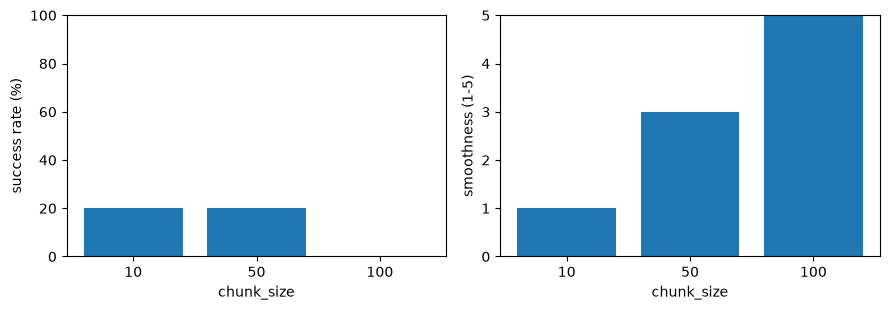

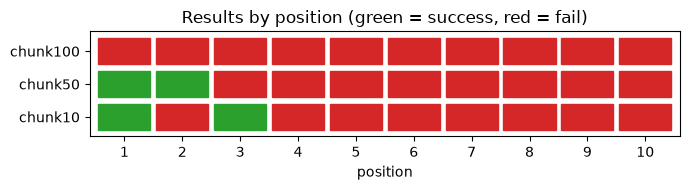

In [63]:
# 조건별 성공률과 부드러움
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
labels = [str(k) for k in summary.index]
axes[0].bar(labels, summary["success_rate"]); axes[0].set_ylim(0, 100)
axes[0].set_xlabel("chunk_size"); axes[0].set_ylabel("success rate (%)")
axes[1].bar(labels, summary["mean_smooth"]); axes[1].set_ylim(0, 5)
axes[1].set_xlabel("chunk_size"); axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()

# 위치별 성공/실패 (행 = chunk_size, 열 = 물체 위치)
fig, ax = plt.subplots(figsize=(7, 2.0))
for row, k in enumerate(CHUNK_SIZES):
    for r in results[k]:
        c = "tab:green" if r["success"] else ("tab:red" if r["success"] is False else "lightgray")
        ax.add_patch(plt.Rectangle((r["position"] - 0.45, row - 0.4), 0.9, 0.8, color=c))
ax.set_xlim(0.4, 10.6); ax.set_ylim(-0.6, len(CHUNK_SIZES) - 0.4)
ax.set_xticks(range(1, 11)); ax.set_yticks(range(len(CHUNK_SIZES)))
ax.set_yticklabels([f"chunk{k}" for k in CHUNK_SIZES]); ax.set_xlabel("position")
ax.set_title("Results by position (green = success, red = fail)")
plt.tight_layout(); plt.show()

### 3-4. 반응성 테스트
조건별로 3회씩 추가로 시도하되, 로봇이 물체를 향해 움직이기 시작한 직후 **물체를 약 5 cm 옮긴다.** 로봇이 새 위치를 따라가는지 관찰한다. (녹화는 선택, 성공률 집계에는 넣지 않음)

반응성 테스트는 녹화가 필요 없으므로 `--strategy.type=base`로 돌린다. `base`는 `--dataset.*` 대신 `--task="..."`와 `--duration=<초>`를 받는다.

```bash
# 반응성 테스트 (K = 10, 50, 100 각각 3회)
lerobot-rollout \
  --strategy.type=base \
  --policy.path=Rlayd36/act_redblock_chunk$K \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --task="Red block pickup and place" \
  --duration=30
```

`[작성]` 아래 `reactivity`를 채운다.

In [64]:
# 조건별 10회 시도 (과제 기준 3회보다 많이 수행)
reactivity = {
    10: [{"trial": 0, "followed": True, "note": ""}, {"trial": 1, "followed": False, "note": ""}, {"trial": 2, "followed": True, "note": ""}, {"trial": 3, "followed": False, "note": ""}, {"trial": 4, "followed": False, "note": ""}, {"trial": 5, "followed": False, "note": ""}, {"trial": 6, "followed": False, "note": ""}, {"trial": 7, "followed": False, "note": ""}, {"trial": 8, "followed": True, "note": ""}, {"trial": 9, "followed": False, "note": ""}],
    50: [{"trial": 0, "followed": True, "note": ""}, {"trial": 1, "followed": True, "note": ""}, {"trial": 2, "followed": False, "note": ""}, {"trial": 3, "followed": False, "note": ""}, {"trial": 4, "followed": False, "note": ""}, {"trial": 5, "followed": False, "note": ""}, {"trial": 6, "followed": False, "note": ""}, {"trial": 7, "followed": False, "note": ""}, {"trial": 8, "followed": False, "note": ""}, {"trial": 9, "followed": True, "note": ""}],
    100: [{"trial": 0, "followed": True, "note": ""}, {"trial": 1, "followed": True, "note": ""}, {"trial": 2, "followed": False, "note": ""}, {"trial": 3, "followed": False, "note": ""}, {"trial": 4, "followed": False, "note": ""}, {"trial": 5, "followed": False, "note": ""}, {"trial": 6, "followed": False, "note": ""}, {"trial": 7, "followed": False, "note": ""}, {"trial": 8, "followed": True, "note": ""}, {"trial": 9, "followed": True, "note": ""}],
}
react_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in reactivity.items()], ignore_index=True)
print(react_df.groupby("chunk_size")["followed"].apply(lambda s: f"{int(s.fillna(False).sum())}/{len(s)}"))
react_df

chunk_size
10     3/10
50     3/10
100    4/10
Name: followed, dtype: object


,trial,followed,note,chunk_size
0,0,True,,10
1,1,False,,10
2,2,True,,10
3,3,False,,10
4,4,False,,10
5,5,False,,10
6,6,False,,10
7,7,False,,10
8,8,True,,10
9,9,False,,10


### 3-5. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
chunk_size에 따른 **동작 차이가 잘 드러나는 장면**을 조건별로 하나씩 GIF로 만들어 `images/`에 올리고 아래에 삽입한다. (예: chunk10의 떨림, chunk100의 청크 경계 튐)

![chunk10](images/hw3_chunk10.gif)
![chunk50](images/hw3_chunk50.gif)
![chunk100](images/hw3_chunk100.gif)

## 4. 고찰
각 질문에 3~5문장으로 답한다. 가능하면 3절의 수치나 영상 장면을 근거로 든다.

**4-1. 가설 검증** — 성공률이 가장 높은 조건은 무엇이었는가? 1-2의 가설과 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.

성공률은 chunk10 20%(2/10), chunk50 20%(2/10), chunk100 0%(0/10)로, chunk10과 chunk50이 공동 1위였다. "chunk50이 가장 높을 것"이라는 가설은 절반만 맞았다. chunk100이 가장 낮을 것이라는 예상은 맞았지만, chunk10이 chunk50과 같은 성공률을 보인 점은 예상과 달랐다. 다만 두 조건의 실패 양상은 전혀 달랐다. chunk10은 실패 8회 중 5회가 "시작 자세에서 일어나지 못함"이었고, chunk50은 실패 8회 중 7회가 "잘못된 위치로 감"이었다. 또 세 조건 모두 성공률이 낮고 차이가 1~2회에 불과하다. 따라서 10회 평가만으로는 chunk10과 chunk50의 우열을 판단하기 어렵다. 이번 결과에서 확실히 말할 수 있는 것은 "chunk100(temporal ensemble 없음)이 가장 나빴다"는 점 정도다.

**4-2. 짧은 청크의 문제** — chunk_size=10에서 관찰된 동작의 특징(떨림, 머뭇거림, 경로 이탈 등)을 compounding error 개념으로 설명하라.

chunk10의 가장 두드러진 특징은 10회 중 5회에서 로봇이 시작 자세에서 팔을 들어 올리지 못하고 거의 제자리에 머문 것이다. chunk10은 0.33초(10스텝) 분량만 예측하고 바로 다시 관측한다. 그래서 시작 자세에서 "아주 조금만 움직이는" 청크를 예측하면, 다음 관측도 거의 같은 시작 자세가 되어 다시 비슷한 작은 행동을 예측하는 루프에 빠진다. 시연 데이터의 시작 부분에는 사람이 잠시 멈춰 있던 구간이 있어서, 짧은 시야(horizon)의 정책은 "지금은 가만히 있는다"를 정답으로 배웠을 가능성이 크다. 이것은 매 결정의 작은 오차가 다음 관측에 반영되어 누적되는 compounding error가 "정지 상태"라는 형태로 나타난 것이다. 결정 횟수가 에피소드당 약 58회로 많아서, 이런 작은 편향이 쌓여 궤적을 벗어나기도 쉽다. 일어난 경우에도 잘못된 위치로 가거나(2회) 블록 앞에서 파지에 실패(1회)했다.

**4-3. 긴 청크의 대가** — chunk_size=100에서 청크가 바뀌는 순간 동작이 끊기거나 튀는 현상이 있었는가? 반응성 테스트 결과와 함께 설명하라.

chunk100은 성공이 한 번도 없었고, 실패 10회 중 6회가 "잘못된 위치로 감"이었다. chunk100은 한 번 추론하면 3.33초 동안 새 관측 없이(open-loop) 그 궤적을 그대로 실행한다. 그래서 첫 청크의 방향이 조금만 틀려도 블록에서 멀어진 채 수정하지 못한다. 블록 위치까지 간 경우에도 잡으러 내려가지 않고 멈추거나(9번), 파지에 실패하거나(10번), 집은 뒤 옮기다 떨어뜨리거나(2번), 시간 초과(1번)로 끝났다. 정밀하게 보정해야 하는 파지·운반 구간에서 청크 하나가 너무 길어 피드백을 받지 못한 것이다. 반응성 테스트에서는 chunk100이 4/10으로 오히려 chunk10·chunk50(각 3/10)보다 조금 높았다. 이는 "chunk10이 가장 잘 따라갈 것"이라는 가설과 다르다. 다만 chunk10은 애초에 시작 자세에서 일어나지 못하는 경우가 많았고, 세 조건 모두 기본 성공률이 낮았다. 그래서 반응성 테스트 결과는 청크 길이에 따른 반응 속도보다 정책 자체의 위치 일반화 능력에 더 크게 좌우된 것으로 보인다.

**4-4. 오프라인 손실과 실제 성능** — 2-3의 `l1_loss`가 낮은 조건이 실로봇 성공률도 높았는가? 그렇지 않다면 이유는 무엇이라고 생각하는가?

최종 l1_loss는 chunk10 0.034 < chunk50 0.042 < chunk100 0.047 순서였다. 하지만 성공률은 chunk10과 chunk50이 같았고, chunk10은 손실이 가장 낮은데도 절반이 시작 자세에서 멈췄다. 따라서 오프라인 손실의 순서가 실로봇 성능을 그대로 예측하지는 못했다. 첫째, 짧은 청크는 가까운 미래만 맞히면 되므로 손실이 낮게 나오는 것이 당연하다. 즉 청크 길이가 다르면 손실끼리 공정하게 비교하기 어렵다. 둘째, l1_loss는 시연 데이터의 관측을 넣었을 때 한 번 예측한 결과의 오차(open-loop, teacher forcing)다. 실제 로봇에서는 정책의 행동이 다음 관측을 바꾸기 때문에 오차가 누적되는 closed-loop 효과가 생기는데, 손실에는 이것이 반영되지 않는다. 셋째, 이 값은 검증 손실이 아니라 학습 데이터에 대한 손실이다. 약 27 epoch 동안 학습했기 때문에, 시연에 없던 위치에서의 일반화 성능은 알 수 없다.

**4-5. 내 태스크에 맞는 chunk_size** — 본인 태스크의 길이와 정밀도 요구 수준을 고려할 때 어떤 chunk_size가 적합한가? 실험하지 않은 값(예: 30)을 제안해도 된다.

이 태스크는 평균 약 19.5초 동안 블록에 접근·파지·운반·내려놓기를 하며, 특히 파지 단계에서 수 cm 이내의 정밀한 위치 보정이 필요하다. chunk100을 그대로 실행하면 3.3초 동안 보정할 수 없어 성공률이 0%였다. 같은 chunk100 정책에 temporal ensemble을 적용하자 성공률이 40%로 가장 높았다. 즉 "긴 청크로 예측하되, 실행은 자주 다시 관측하면서 하는 것"이 이 태스크에 가장 잘 맞았다. 따라서 chunk_size는 30~50(1~1.7초) 정도로 두고 temporal ensemble을 함께 쓰는 것을 제안한다. temporal ensemble의 추론 부담이 크다면 chunk_size=50, n_action_steps=10~15처럼 청크의 앞부분만 실행하고 다시 추론하는 방식도 대안이다. 또 세 조건 모두 "잘못된 위치로 감"이 가장 흔한 실패였으므로, chunk_size 조정과 함께 위치 3~9 근처의 시연 데이터를 보강하는 것도 필요해 보인다.


## 5. Temporal ensemble
chunk_size=100 정책을 그대로 두고 추론 방식만 바꿔, 매 스텝 추론하며 겹치는 예측을 가중 평균한다. 재학습은 필요 없다.

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=Rlayd36/act_redblock_chunk100 \
  --policy.n_action_steps=1 \
  --policy.temporal_ensemble_coeff=0.01 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --dataset.repo_id=Rlayd36/rollout_act_redblock_chunk100_te \
  --dataset.single_task="Red block pickup and place" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15
```

> `lerobot-rollout`은 `--policy.path`로 불러온 설정 위에 `--policy.*` 값을 덮어쓴다. ACT는 `temporal_ensemble_coeff`를 설정하면 `n_action_steps=1`이어야 하며, 다른 값이면 시작할 때 오류를 낸다.

3-1과 같은 위치·순서로 10회 평가하고 chunk100 결과와 성공률·부드러움·추론 지연을 비교한다.

**결과 비교**

같은 chunk100 가중치에 temporal ensemble만 적용했는데, 성공률이 0%(0/10)에서 40%(4/10)로 크게 올랐다. 위치 1, 2, 8, 10에서 성공했다. chunk100은 한 번 예측한 3.33초 궤적을 관측 없이 끝까지 실행하므로, 첫 방향이 틀리면 블록에 다가가는 도중에 고칠 수 없었다. 반면 temporal ensemble은 매 스텝(30 Hz) 새로 관측해 추론하고, 그 시점을 예측한 여러 청크를 지수 가중 평균(coeff 0.01)해서 실행한다. 그래서 파지 직전처럼 정밀한 보정이 필요한 구간에서도 계속 궤도를 수정할 수 있었다. 실제로 chunk100에서 나온 "집었는데 시간 초과", "옮기다 떨어뜨림", "잡으러 내려가지 않음" 같은 실패가 temporal ensemble에서는 나오지 않았다. 평가 에피소드 평균 길이도 28.3초에서 20.7초로 짧아져, 성공한 회차가 제한 시간 전에 일찍 끝났음을 보여 준다. 부드러움은 두 조건 모두 5점으로 체감 차이는 없었다. temporal ensemble은 여러 예측을 평균하므로 청크 경계에서 튀는 현상을 줄이는 효과가 있다. 추론 지연(한 번 추론에 걸리는 시간)은 같은 모델이라 거의 같지만, 추론 횟수는 에피소드당 약 6회에서 매 스텝(약 600회)으로 100배 늘어 GPU 연산 부담이 훨씬 크다. 이번 평가에서는 제어 주기가 밀려 동작이 끊기는 현상은 관찰되지 않았다. 다만 위치 3~7에서는 여전히 "잘못된 위치로 감"으로 실패했다. temporal ensemble은 실행 방식의 문제는 해결하지만, 정책이 블록 위치를 잘못 인식하는 일반화 문제까지 해결하지는 못한다.

In [65]:
# 5. Temporal ensemble 결과 입력
TE_EVAL_DATASET = f"{HF_USER}/rollout_act_redblock_chunk100_te_20261117_001835"
te_results = [   # 3-1과 같은 위치·순서
    {"episode": 0, "position": 1, "success": True, "smooth": 5, "note": ""},
    {"episode": 1, "position": 2, "success": True, "smooth": 5, "note": ""},
    {"episode": 2, "position": 3, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
    {"episode": 3, "position": 4, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
    {"episode": 4, "position": 5, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
    {"episode": 5, "position": 6, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
    {"episode": 6, "position": 7, "success": False, "smooth": 5, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
    {"episode": 7, "position": 8, "success": True, "smooth": 5, "note": ""},
    {"episode": 8, "position": 9, "success": False, "smooth": 5, "note": "블록 위치까지 정상적으로 갔으나 파지에 실패"},
    {"episode": 9, "position": 10, "success": True, "smooth": 5, "note": ""},
]

te_info = load_json(TE_EVAL_DATASET, "meta/info.json", repo_type="dataset") if TE_EVAL_DATASET else None
if te_info:
    n_ep = te_info.get("total_episodes")
    print(f"temporal ensemble 에피소드 {n_ep}개 ->", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

te_df = pd.DataFrame(te_results)
if te_df["success"].notna().all():
    print(f"temporal ensemble 성공률: {te_df['success'].astype(float).mean()*100:.0f}%, 부드러움 평균: {te_df['smooth'].mean():.1f}")
    print(f"chunk100 성공률        : {summary.loc[100, 'success_rate']:.0f}%, 부드러움 평균: {summary.loc[100, 'mean_smooth']:.1f}")
else:
    print("te_results를 실제 결과로 채울 것")

temporal ensemble 에피소드 10개 -> 통과
temporal ensemble 성공률: 40%, 부드러움 평균: 5.0
chunk100 성공률        : 0%, 부드러움 평균: 5.0


## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [66]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in [*EVAL_DATASETS.values(), TE_EVAL_DATASET] if r),
}
for k in CHUNK_SIZES:
    check_items[f"chunk{k} 정책 업로드됨 (config.json, model.safetensors)"] = (
        file_ok(POLICY_REPOS[k], "config.json", "model") and file_ok(POLICY_REPOS[k], "model.safetensors", "model"))
    check_items[f"chunk{k} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"chunk{k} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"chunk{k} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
check_items["통제 변수 일치 (1-3)"] = all(cfg_df[c].nunique(dropna=False) == 1 for c in ["dataset", "steps", "batch_size", "seed"])
check_items["반응성 테스트 9회 입력"] = all(r["followed"] is not None for v in reactivity.values() for r in v)
check_items["temporal ensemble 평가 데이터셋 에피소드 10개"] = bool(te_info) and te_info.get("total_episodes") == 10
check_items["temporal ensemble 회차별 결과 10개 입력"] = all(r["success"] is not None for r in te_results)
check_items["temporal ensemble 실패 회차에 원인 기재"] = all(r["note"].strip() for r in te_results if r["success"] is False)

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 학습 데이터셋 접근 가능 (public)
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] chunk10 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk10 평가 데이터셋 에피소드 10개
[통과] chunk10 회차별 결과 10개 입력
[통과] chunk10 실패 회차에 원인 기재
[통과] chunk50 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk50 평가 데이터셋 에피소드 10개
[통과] chunk50 회차별 결과 10개 입력
[통과] chunk50 실패 회차에 원인 기재
[통과] chunk100 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk100 평가 데이터셋 에피소드 10개
[통과] chunk100 회차별 결과 10개 입력
[통과] chunk100 실패 회차에 원인 기재
[통과] 통제 변수 일치 (1-3)
[통과] 반응성 테스트 9회 입력
[통과] temporal ensemble 평가 데이터셋 에피소드 10개
[통과] temporal ensemble 회차별 결과 10개 입력
[통과] temporal ensemble 실패 회차에 원인 기재

모두 통과
